In [8]:
import pandas, sklearn; print("ok")

ok


In [9]:
import yfinance as yf

df = yf.download("LUCK.KA", start="2015-01-01")
print(df.shape)
df.head()

[*********************100%***********************]  1 of 1 completed

(3054, 5)


Price,Close,High,Low,Open,Volume
Ticker,LUCK.KA,LUCK.KA,LUCK.KA,LUCK.KA,LUCK.KA
Date,,,,,
2015-01-01,488.476318,492.281762,476.631862,476.631862,457800
2015-01-02,488.723724,494.469924,483.291432,489.950959,368000
2015-01-05,484.014435,492.805001,483.291391,490.902279,245100
2015-01-06,475.528259,487.096812,472.541001,480.437285,501100
2015-01-07,482.730133,487.087354,474.967023,475.528323,465700


#Imported data of LUCK from yahoo finance


MultiIndex([( 'Close', 'LUCK.KA'),
            (  'High', 'LUCK.KA'),
            (   'Low', 'LUCK.KA'),
            (  'Open', 'LUCK.KA'),
            ('Volume', 'LUCK.KA')],
           names=['Price', 'Ticker'])
Date
2025-03-03    3.959836
2025-02-26    0.799499
2025-04-10    0.794766
2025-05-12    0.100010
2025-02-14    0.100004
2026-04-08    0.099995
2026-03-10    0.099835
2026-03-09    0.099389
2026-03-02    0.096902
2025-06-24    0.093981
Name: Close, dtype: float64


<Axes: xlabel='Date'>

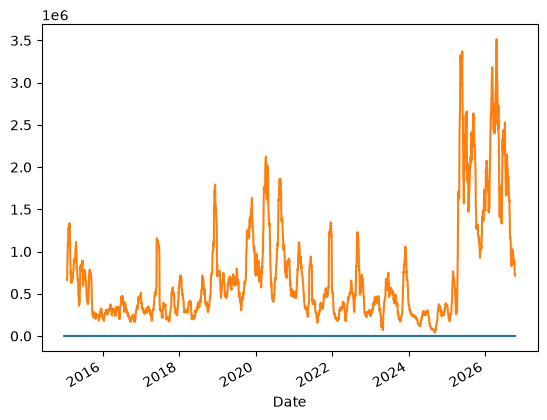

In [10]:
print(df.columns)
df.columns = df.columns.droplevel(1)
ret = df["Close"].pct_change()
print(ret.abs().nlargest(10))
df["Close"].plot()
df["Volume"].rolling(20).mean().plot()


#Plot the LUCK values to check for discrepancies and organise the data.

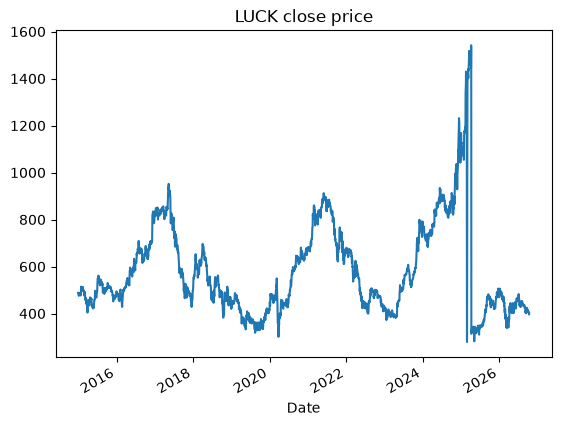

Date
2025-03-03    3.959836
2025-02-26    0.799499
2025-04-10    0.794766
2025-05-12    0.100010
2025-02-14    0.100004
2026-04-08    0.099995
2026-03-10    0.099835
2026-03-09    0.099389
2026-03-02    0.096902
2025-06-24    0.093981
Name: Close, dtype: float64
0.05566470203012443


In [11]:
import matplotlib.pyplot as plt

df["Close"].plot(title="LUCK close price")
plt.show()

ret = df["Close"].pct_change()
print(ret.abs().nlargest(10))
print((ret == 0).mean())

#Plot LUCK closing price and we observe the discrepancy created by share split of 5:1.

In [12]:
ret = df["Close"].pct_change()
big = ret.abs().nlargest(10)
print(big.sort_index())
print((ret == 0).mean())

d = big.index[0]
i = df.index.get_loc(d)
print(df.iloc[i-5:i+6][["Close", "Volume"]])

Date
2025-02-14    0.100004
2025-02-26    0.799499
2025-03-03    3.959836
2025-04-10    0.794766
2025-05-12    0.100010
2025-06-24    0.093981
2026-03-02    0.096902
2026-03-09    0.099389
2026-03-10    0.099835
2026-04-08    0.099995
Name: Close, dtype: float64
0.05566470203012443
Price             Close   Volume
Date                            
2025-02-24  1419.655762  1462920
2025-02-25  1426.424072   421255
2025-02-26   285.999817  1248690
2025-02-27   281.494141   796900
2025-02-28   278.992493   936540
2025-03-03  1383.757080   161766
2025-03-04  1383.757080        0
2025-03-05  1404.904541   284831
2025-03-06  1405.511841   178135
2025-03-07  1419.244263   323720
2025-03-10  1418.793701   129248


#Check for unusual gains and find discrepancies.

rows dropped (zero volume): 168
rows left: 2885
Date
2025-05-12    0.100010
2025-02-14    0.100004
2026-04-08    0.099995
2026-03-10    0.099835
2026-03-09    0.099389
2026-03-02    0.096902
2025-06-24    0.093981
2026-04-01    0.091689
2025-01-02    0.083563
2025-10-14    0.082943
Name: Close, dtype: float64


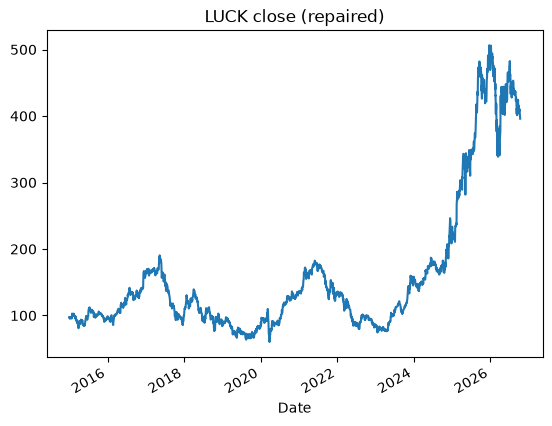

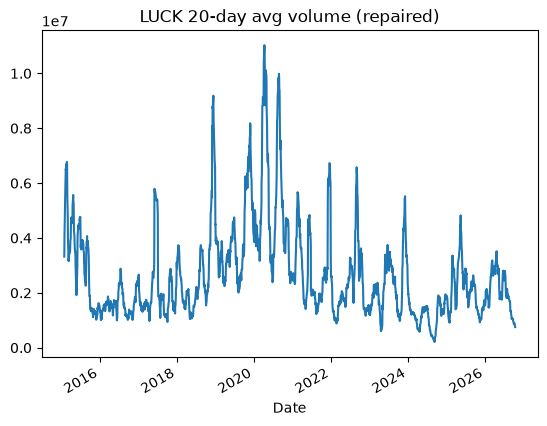

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/LUCK.csv", index_col="Date", parse_dates=True)

split_date = pd.Timestamp("2025-04-10")
bad_rows = pd.to_datetime(["2025-02-26", "2025-02-27", "2025-02-28"])
price_cols = ["Open", "High", "Low", "Close"]

old = (df.index < split_date) & ~df.index.isin(bad_rows)
df.loc[old, price_cols] = df.loc[old, price_cols] / 5
df.loc[old, "Volume"] = df.loc[old, "Volume"] * 5

before = len(df)
df = df[df["Volume"] > 0]
print("rows dropped (zero volume):", before - len(df))
print("rows left:", len(df))

ret = df["Close"].pct_change()
print(ret.abs().nlargest(10))

df["Close"].plot(title="LUCK close (repaired)")
plt.show()
df["Volume"].rolling(20).mean().plot(title="LUCK 20-day avg volume (repaired)")
plt.show()

df.to_csv("../data/LUCK_clean.csv")

#Correct the data and find repaired values and plot a repaired graph

In [14]:
import pandas as pd

df = pd.read_csv("../data/LUCK_clean.csv", index_col="Date", parse_dates=True)

print("first date:", df.index.min())
print("last date:", df.index.max())
print("sorted oldest to newest:", df.index.is_monotonic_increasing)
print("duplicate dates:", df.index.duplicated().sum())
print("missing values:")
print(df.isna().sum())
print("rows where High < Low:", (df["High"] < df["Low"]).sum())

ret = df["Close"].pct_change()
print("zero-change share:", (ret == 0).mean())

df.info()
print(df.describe())

first date: 2015-01-01 00:00:00
last date: 2026-10-13 00:00:00
sorted oldest to newest: True
duplicate dates: 0
missing values:
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
rows where High < Low: 0
zero-change share: 0.0006932409012131716
<class 'pandas.DataFrame'>
DatetimeIndex: 2885 entries, 2015-01-01 to 2026-10-13
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2885 non-null   float64
 1   High    2885 non-null   float64
 2   Low     2885 non-null   float64
 3   Open    2885 non-null   float64
 4   Volume  2885 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 135.2 KB
             Close         High          Low         Open        Volume
count  2885.000000  2885.000000  2885.000000  2885.000000  2.885000e+03
mean    158.560729   161.005619   156.547022   158.834176  2.677879e+06
std     105.928124   107.693764   104.567465   106.183671  3.001686e+06
min      60.180005   

#Verify once again that the data is now majorly fault free by having no duplicate dates,missing values, correct sorting,etc